# Data-Science-Projekt: Schritt-für-Schritt-Vorlage

**Beispiel:** Kündigungsvorhersage (Churn Prediction). Die Daten sind **synthetisch**, damit das Notebook sofort läuft. Für ein eigenes Projekt ersetzt du Schritt 2 und passt die `TODO`-Stellen an.

| Nr. | Schritt | Ergebnis |
|---|---|---|
| 0 | Projekt einrichten | Ordnerstruktur, Konfiguration |
| 1 | Problemverständnis | Projektsteckbrief |
| 2 | Datenbeschaffung | Rohdaten |
| 3 | Datenverständnis | Qualitätsbericht |
| 4 | Datenbereinigung | bereinigte Daten |
| 5 | Datenaufteilung und EDA | Erkenntnisse |
| 6 | Feature Engineering | Pipeline |
| 7 | Modellierung | bestes Modell |
| 8 | Evaluation | Go / No-Go |
| 9 | Deployment | gespeichertes Modell, API |
| 10 | Monitoring | Drift-Prüfung |
| 11 | Dokumentation | Bericht, README |

## Schritt 0: Projekt einrichten

**Aufgaben**
- Git-Repository und virtuelle Umgebung anlegen
- Ordnerstruktur erstellen
- Zufallswert (Seed) und Pfade zentral festlegen

**Checkliste**
- [ ] `.gitignore` schließt Daten, Modelle und Passwörter aus
- [ ] `requirements.txt` ist vorhanden

In [1]:
# Bibliotheken importieren
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Zentrale Einstellungen
RANDOM_STATE = 42
PROJECT_DIR = Path("churn-projekt")

# Ordnerstruktur anlegen
folders = ["data/raw", "data/interim", "data/processed", "notebooks", "src",
           "models", "reports/figures", "app", "tests"]
for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

# Wichtige Dateien nicht versionieren
(PROJECT_DIR / ".gitignore").write_text("data/\nmodels/\n.env\n.venv/\n__pycache__/\n")
print(sorted(p.name for p in PROJECT_DIR.iterdir()))

['.gitignore', 'README.md', 'app', 'data', 'models', 'notebooks', 'reports', 'requirements.txt', 'src', 'tests']


## Schritt 1: Problemverständnis

**Ziel:** Vor der ersten Codezeile klären, welche Entscheidung unterstützt werden soll.

| Frage | Beispielantwort |
|---|---|
| Geschäftsproblem | Zu viele Kunden kündigen. |
| Entscheidung | Welche Kunden erhalten ein Bindungsangebot? |
| Zielvariable | `churn` (1 = gekündigt) |
| Prognosezeitpunkt | Vor dem Angebot; nur bis dahin bekannte Daten nutzen |
| Geschäftskennzahl | Kosten durch Kündigungen und Angebote |
| Modellmetrik | Recall, Precision, ROC-AUC, Kosten |
| Erfolgskriterium | Geringere Kosten als die beste einfache Strategie |
| Risiken | Datenschutz (DSGVO), Fairness, Datenleck |

**Checkliste**
- [ ] Ansprechpartner und Termine sind bekannt
- [ ] Erfolgskriterium ist **vor** der Modellierung festgelegt

In [2]:
# Kosten je Fehlerart (TODO: mit dem Fachbereich abstimmen)
COST_MISSED_CHURN = 500   # Kündigung nicht erkannt
COST_FALSE_ALARM = 100    # unnötiges Angebot

## Schritt 2: Datenbeschaffung

**Aufgaben**
- Datenquellen bestimmen (SQL, API, CSV)
- Zugriffsrechte und Rechtsgrundlage prüfen
- Rohdaten unverändert in `data/raw/` speichern

**Checkliste**
- [ ] Quelle, Abrufdatum und Zeitraum sind dokumentiert
- [ ] Nur notwendige personenbezogene Daten werden verwendet

In [3]:
# TODO: durch echte Daten ersetzen, z. B. pd.read_csv(...) oder pd.read_sql(...)
rng = np.random.default_rng(RANDOM_STATE)
n = 3000
raw = pd.DataFrame({
    "customer_id": np.arange(1, n + 1),
    "tenure_months": rng.integers(1, 72, n),
    "monthly_fee": rng.normal(60, 18, n).clip(15).round(2),
    "support_calls": rng.poisson(1.5, n),
    "contract": rng.choice(["monatlich", "jährlich"], n, p=[0.65, 0.35]),
})
logit = (-1.0 - 0.04 * raw["tenure_months"] + 0.025 * raw["monthly_fee"]
         + 0.45 * raw["support_calls"] - 1.2 * raw["contract"].eq("jährlich"))
raw["churn"] = rng.binomial(1, 1 / (1 + np.exp(-logit)))

# Typische Qualitätsprobleme einbauen
raw.loc[rng.choice(n, 90, replace=False), "monthly_fee"] = np.nan
raw.loc[rng.choice(n, 200, replace=False), "contract"] = " Monatlich "
raw = pd.concat([raw, raw.sample(25, random_state=RANDOM_STATE)], ignore_index=True)

raw.to_csv(PROJECT_DIR / "data/raw/customers.csv", index=False)
raw.head()

,customer_id,tenure_months,monthly_fee,support_calls,contract,churn
0,1,7,77.33,2,monatlich,0
1,2,55,NaN,2,jährlich,0
2,3,47,44.63,1,monatlich,1
3,4,32,68.27,2,monatlich,1
4,5,31,77.79,1,jährlich,0


## Schritt 3: Datenverständnis

**Leitfragen**
- Was stellt eine Zeile dar?
- Welche Typen, fehlenden Werte, Duplikate und unplausiblen Werte gibt es?
- Wie ist die Zielvariable verteilt?

**Checkliste**
- [ ] Datenwörterbuch erstellt
- [ ] Qualitätsprobleme notiert (noch nichts verändert)

In [4]:
# Qualitätsbericht erstellen
quality = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                        "unique": raw.nunique()})
display(quality)
print("Form:", raw.shape)
print("Doppelte Zeilen:", raw.duplicated().sum())
print(raw["contract"].value_counts())
print("Churn-Anteil:", round(raw["churn"].mean(), 3))

,dtype,missing,unique
customer_id,int64,0,3000
tenure_months,int64,0,71
monthly_fee,float64,90,2337
support_calls,int64,0,8
contract,str,0,3
churn,int64,0,2


Form: (3025, 6)
Doppelte Zeilen: 25
contract
monatlich      1837
jährlich        983
 Monatlich      205
Name: count, dtype: int64
Churn-Anteil: 0.369


## Schritt 4: Datenbereinigung

**Aufgaben**
- Duplikate entfernen, Texte und Datentypen vereinheitlichen
- Unplausible Werte prüfen
- Über fehlende Werte entscheiden

**Wichtig:** Imputation mit Mittelwert oder Median wird **nicht hier**, sondern in der Pipeline (Schritt 6) gelernt. Sonst entsteht ein Datenleck.

**Checkliste**
- [ ] Bereinigung liegt als Funktion vor
- [ ] Jede Entscheidung ist begründet

In [5]:
def clean_data(df):
    """Bereinigt die Rohdaten, ohne aus den Daten statistische Werte zu lernen."""
    df = df.drop_duplicates().copy()
    df["contract"] = df["contract"].str.strip().str.lower()
    return df

data = clean_data(raw)

# Automatische Prüfungen
assert data["customer_id"].is_unique
assert set(data["contract"]) == {"monatlich", "jährlich"}
assert data["churn"].isin([0, 1]).all()

data.to_csv(PROJECT_DIR / "data/interim/customers_clean.csv", index=False)
print("Zeilen vorher/nachher:", len(raw), "->", len(data))

Zeilen vorher/nachher: 3025 -> 3000


## Schritt 5a: Testdaten zurücklegen

Die Aufteilung erfolgt **vor** der Analyse von Zusammenhängen, damit die Testdaten keine Entscheidungen beeinflussen. Drei Teile: **Training** (60 %), **Validierung** (20 %), **Test** (20 %). Bei Zeitreihen wird nach Zeit getrennt.

In [6]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["customer_id", "churn"])
y = data["churn"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)
print(len(X_train), len(X_val), len(X_test))

1800 600 600


## Schritt 5b: Explorative Datenanalyse (EDA)

Nur mit den **Trainingsdaten**.

**Leitfragen**
- Welche Merkmale unterscheiden Kündiger von Nicht-Kündigern?
- Gibt es Korrelationen zwischen Merkmalen?
- Welche Hypothesen ergeben sich?

**Checkliste**
- [ ] Jedes Diagramm hat Titel, Achsenbeschriftung und eine Aussage
- [ ] Korrelation wird nicht als Ursache interpretiert

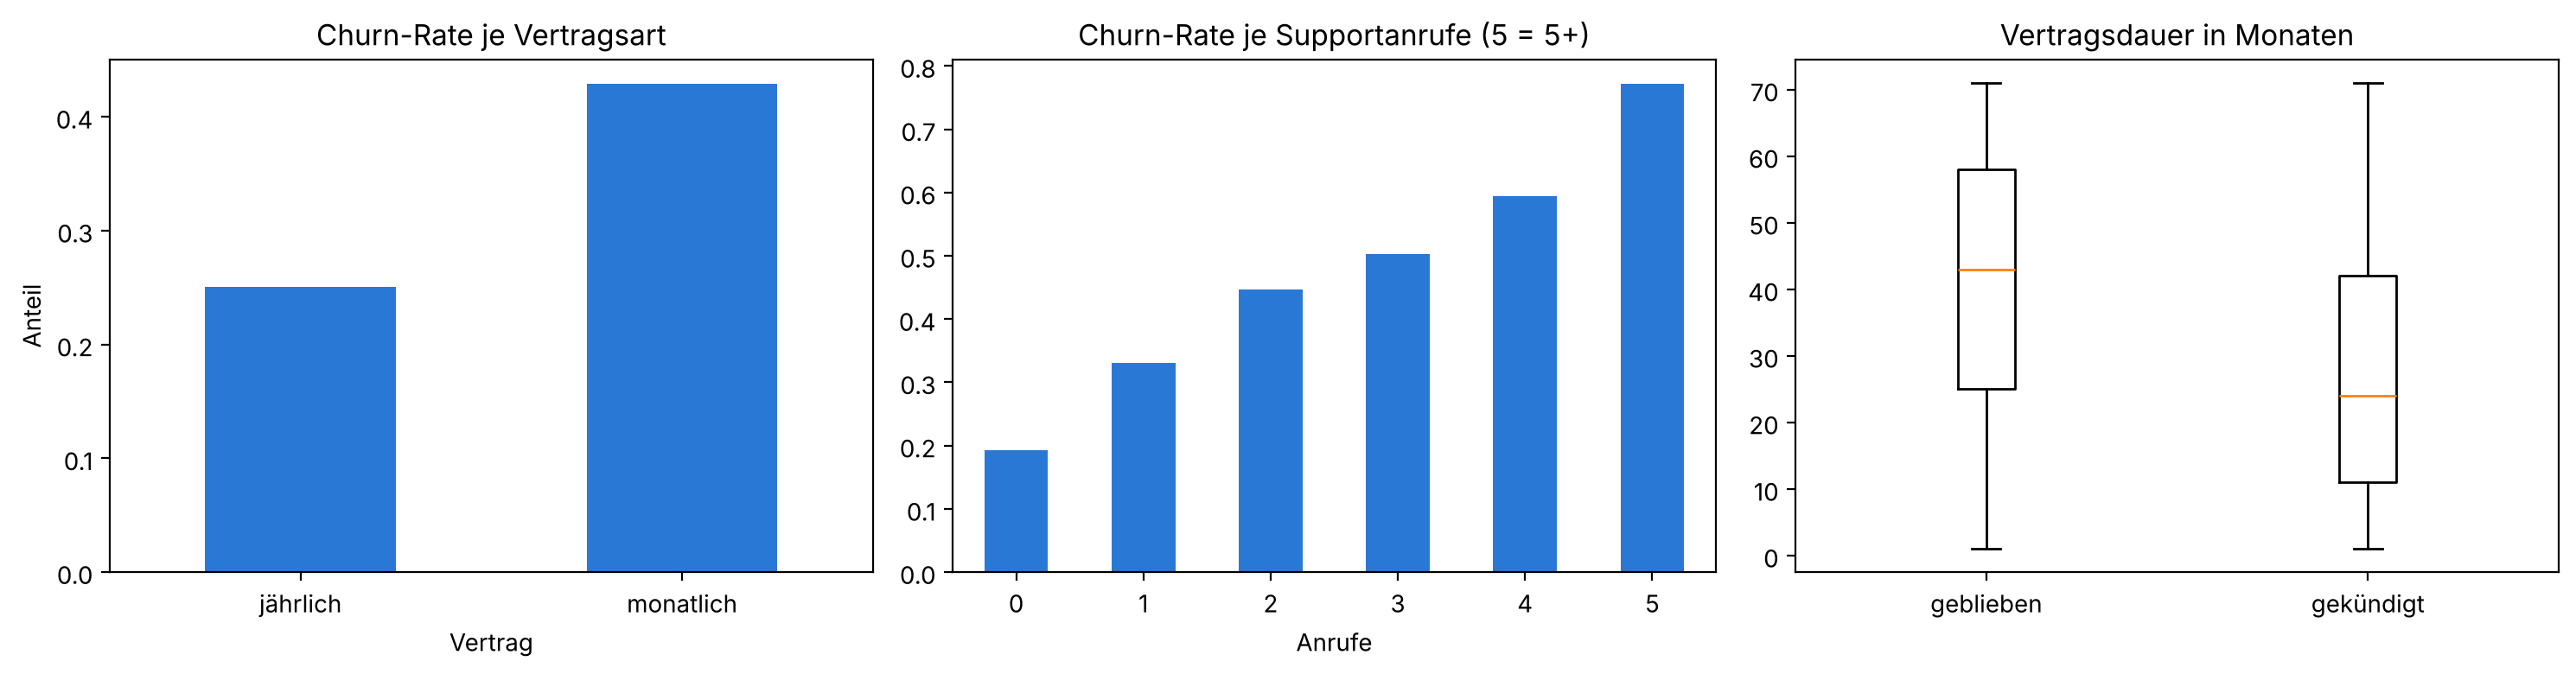

In [7]:
train = X_train.assign(churn=y_train)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Kündigungsrate nach Vertragsart
train.groupby("contract")["churn"].mean().plot(kind="bar", ax=axes[0], color="#2a78d6", rot=0)
axes[0].set_title("Churn-Rate je Vertragsart")
axes[0].set_xlabel("Vertrag"); axes[0].set_ylabel("Anteil")

# Kündigungsrate nach Anzahl der Supportanrufe
train.groupby(train["support_calls"].clip(upper=5))["churn"].mean().plot(
    kind="bar", ax=axes[1], color="#2a78d6", rot=0)
axes[1].set_title("Churn-Rate je Supportanrufe (5 = 5+)")
axes[1].set_xlabel("Anrufe")

# Vertragsdauer nach Zielvariable
axes[2].boxplot([train.loc[train["churn"] == k, "tenure_months"] for k in [0, 1]])
axes[2].set_xticks([1, 2], ["geblieben", "gekündigt"])
axes[2].set_title("Vertragsdauer in Monaten")
plt.tight_layout()
fig.savefig(PROJECT_DIR / "reports/figures/eda.png", dpi=150)
plt.show()

## Schritt 6: Feature Engineering und Pipeline

**Aufgaben**
- Neue Merkmale bilden, die zum Prognosezeitpunkt verfügbar sind
- Numerische Werte imputieren und skalieren
- Kategorien kodieren
- Alles in einer `Pipeline` zusammenfassen

**Checkliste**
- [ ] `fit` geschieht ausschließlich auf Trainingsdaten
- [ ] Kein Merkmal enthält Informationen aus der Zukunft

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["tenure_months", "monthly_fee", "support_calls"]
categorical_features = ["contract"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

## Schritt 7: Modellierung

**Vorgehen**
1. **Baseline** festlegen
2. Einfache und komplexere Modelle mit Kreuzvalidierung vergleichen
3. Hyperparameter des besten Kandidaten optimieren

**Checkliste**
- [ ] Jedes Modell wird mit der Baseline verglichen
- [ ] Bei ähnlicher Leistung gewinnt das einfachere Modell

In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

candidates = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Logistische Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                            random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    results.append({"Modell": name, "ROC-AUC": scores.mean(), "Std": scores.std()})
comparison = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
comparison.round(3)

,Modell,ROC-AUC,Std
1,Logistische Regression,0.783,0.016
2,Random Forest,0.751,0.021
0,Baseline,0.500,0.000


In [10]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter der logistischen Regression optimieren
# TODO: bei anderem Sieger im Vergleich Modell und Parameter anpassen
search = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))]),
    param_grid={"model__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc")
search.fit(X_train, y_train)
best_model = search.best_estimator_
print(search.best_params_, round(search.best_score_, 3))

{'model__C': 10} 0.783


## Schritt 8: Evaluation

1. Entscheidungsschwelle auf den **Validierungsdaten** anhand der Kosten wählen
2. **Einmalig** auf den Testdaten bewerten
3. Ergebnis mit dem Erfolgskriterium vergleichen

**Checkliste**
- [ ] Fehler nach Kundengruppen untersucht
- [ ] Ergebnis in Geschäftssprache erklärt
- [ ] Go / No-Go entschieden

In [11]:
def total_cost(y_true, y_pred):
    """Berechnet die Kosten aus verpassten Kündigungen und Fehlalarmen."""
    missed = np.sum((y_true == 1) & (y_pred == 0))
    false_alarm = np.sum((y_true == 0) & (y_pred == 1))
    return missed * COST_MISSED_CHURN + false_alarm * COST_FALSE_ALARM

# Schwelle mit den geringsten Kosten auf den Validierungsdaten suchen
val_proba = best_model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)
threshold = float(thresholds[np.argmin([total_cost(y_val, val_proba >= t) for t in thresholds])])
print("Gewählte Schwelle:", round(threshold, 2))

Gewählte Schwelle: 0.16


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= threshold).astype(int)
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, digits=3))

# Vergleich mit einfachen Strategien
costs = {"Modell": total_cost(y_test, test_pred),
         "Niemandem ein Angebot": total_cost(y_test, np.zeros(len(y_test))),
         "Allen ein Angebot": total_cost(y_test, np.ones(len(y_test)))}
for strategy, cost in costs.items():
    print(f"{strategy:24s}{cost:>10,.0f} €")
decision = "Go" if costs["Modell"] < min(list(costs.values())[1:]) else "No-Go"
print("Entscheidung:", decision)

ROC-AUC: 0.749
[[125 253]
 [ 20 202]]
              precision    recall  f1-score   support

           0      0.862     0.331     0.478       378
           1      0.444     0.910     0.597       222

    accuracy                          0.545       600
   macro avg      0.653     0.620     0.537       600
weighted avg      0.707     0.545     0.522       600

Modell                      35,300 €
Niemandem ein Angebot      111,000 €
Allen ein Angebot           37,800 €
Entscheidung: Go


**Hinweis:** Die Kostenrechnung ist vereinfacht. Sie nimmt an, dass ein Angebot jede erkannte Kündigung verhindert und selbst nichts kostet, wenn der Kunde wirklich kündigen wollte. In der Praxis wird die Wirkung mit einem **A/B-Test** geprüft.

## Schritt 9: Deployment

**Aufgaben**
- Pipeline **und** Schwelle gemeinsam speichern
- Vorhersagefunktion schreiben und testen
- Als API (FastAPI) oder App (Streamlit) bereitstellen, mit Docker verpacken

**Checkliste**
- [ ] Eingaben werden geprüft
- [ ] Bibliotheksversionen sind festgeschrieben

In [13]:
model_path = PROJECT_DIR / "models/churn_model.joblib"
joblib.dump({"pipeline": best_model, "threshold": threshold}, model_path)

def predict_churn(customer: dict, path=model_path):
    """Gibt Wahrscheinlichkeit und Entscheidung für einen Kunden zurück."""
    bundle = joblib.load(path)
    probability = float(bundle["pipeline"].predict_proba(pd.DataFrame([customer]))[0, 1])
    return {"probability": round(probability, 3), "offer": probability >= bundle["threshold"]}

predict_churn({"tenure_months": 3, "monthly_fee": 85.0, "support_calls": 4,
               "contract": "monatlich"})

{'probability': 0.953, 'offer': True}

In [14]:
# Beispiel für eine API-Datei erzeugen
api_code = '''from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd

app = FastAPI()
bundle = joblib.load("models/churn_model.joblib")

class Customer(BaseModel):
    tenure_months: int
    monthly_fee: float
    support_calls: int
    contract: str

@app.post("/predict")
def predict(customer: Customer):
    frame = pd.DataFrame([customer.model_dump()])
    probability = float(bundle["pipeline"].predict_proba(frame)[0, 1])
    return {"probability": probability, "offer": probability >= bundle["threshold"]}
'''
(PROJECT_DIR / "app/main.py").write_text(api_code, encoding="utf-8")
print("Start im Projektordner: uvicorn app.main:app --reload")

Start im Projektordner: uvicorn app.main:app --reload


## Schritt 10: Monitoring und Wartung

**Zu überwachen**
- **Datendrift:** Verändern sich die Eingabedaten?
- **Modellleistung:** Sobald die wahren Ergebnisse bekannt sind
- **Technik:** Fehlerrate, Antwortzeit

Faustregel beim **Population Stability Index (PSI):** unter 0,1 stabil, 0,1 bis 0,25 beobachten, über 0,25 untersuchen.

In [15]:
def population_stability_index(expected, actual, bins=10):
    """Vergleicht zwei Verteilungen; größere Werte bedeuten stärkere Abweichung."""
    expected, actual = np.asarray(expected, float), np.asarray(actual, float)
    expected, actual = expected[~np.isnan(expected)], actual[~np.isnan(actual)]
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.clip(np.histogram(expected, edges)[0] / len(expected), 1e-6, None)
    a = np.clip(np.histogram(actual, edges)[0] / len(actual), 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))

# Simulation: Gebühren steigen um 15 Euro
print("Testdaten:     ", round(population_stability_index(X_train["monthly_fee"], X_test["monthly_fee"]), 3))
print("Preiserhöhung: ", round(population_stability_index(X_train["monthly_fee"], X_test["monthly_fee"] + 15), 3))

Testdaten:      0.028
Preiserhöhung:  0.562


## Schritt 11: Dokumentation und Übergabe

**README-Gliederung:** Problem · Daten · Vorgehen · Ergebnisse · Installation und Start · Grenzen · nächste Schritte

**Abschlusscheckliste**
- [ ] Notebook läuft von oben nach unten fehlerfrei durch
- [ ] Wiederverwendbarer Code liegt in `src/`
- [ ] Tests für Bereinigung und Vorhersage vorhanden
- [ ] Keine Passwörter oder Rohdaten im Repository
- [ ] Ergebnisse für Nicht-Fachleute zusammengefasst

In [16]:
# README-Grundgerüst speichern
sections = ["Problem", "Daten", "Vorgehen", "Ergebnisse", "Installation und Start",
            "Grenzen", "Nächste Schritte"]
readme = "# Churn Prediction\n\n" + "\n\n".join(f"## {s}\n\nTODO" for s in sections) + "\n"
(PROJECT_DIR / "README.md").write_text(readme, encoding="utf-8")
(PROJECT_DIR / "requirements.txt").write_text(
    "numpy\npandas\nmatplotlib\nscikit-learn\njoblib\nfastapi\nuvicorn\n")
print("Projektvorlage vollständig")

Projektvorlage vollständig
